<a href="https://colab.research.google.com/github/Series-Parallel/Machine_in_control/blob/main/cartpole_pid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
# ---- Cell 1: cart-pole dynamics (plain NumPy) ----
# State s = [x, x_dot, theta, theta_dot]; theta = 0 is UPRIGHT (unstable), positive = leaning right.
# Input F = horizontal force on the cart (N), positive = push right.
# Lagrangian derivation gives (l = half pole length, point-mass-like pole on a rigid rod):
#   temp      = (F + m*l*th_dot^2*sin(th)) / (M+m)
#   th_ddot   = (g*sin(th) - cos(th)*temp) / (l*(4/3 - m*cos(th)^2/(M+m)))
#   x_ddot    = temp - m*l*th_ddot*cos(th)/(M+m)
import numpy as np
import matplotlib.pyplot as plt

class CartPole:
    def __init__(self, M=1.0, m=0.1, l=0.5, g=9.81, dt=0.005):
        self.M, self.m, self.l, self.g, self.dt = M, m, l, g, dt

    def deriv(self, s, F):
        x, xd, th, thd = s
        M, m, l, g = self.M, self.m, self.l, self.g
        sin, cos = np.sin(th), np.cos(th)
        temp = (F + m * l * thd**2 * sin) / (M + m)
        thdd = (g * sin - cos * temp) / (l * (4/3 - m * cos**2 / (M + m)))
        xdd = temp - m * l * thdd * cos / (M + m)
        return np.array([xd, xdd, thd, thdd])

    def step(self, s, F):
        """One RK4 step (force held constant over dt, like a zero-order-hold controller)."""
        dt = self.dt
        k1 = self.deriv(s, F)
        k2 = self.deriv(s + 0.5*dt*k1, F)
        k3 = self.deriv(s + 0.5*dt*k2, F)
        k4 = self.deriv(s + dt*k3, F)
        return s + dt/6 * (k1 + 2*k2 + 2*k3 + k4)

# Sanity check: with no control, a 0.05 rad tilt must fall over (upright is unstable).
cp = CartPole(); s = np.array([0, 0, 0.05, 0.0])
for _ in range(int(1.0/cp.dt)): s = cp.step(s, 0.0)
print(f"No control, after 1 s: theta = {s[2]:.2f} rad (started at 0.05) -> falls, as expected")

No control, after 1 s: theta = 1.26 rad (started at 0.05) -> falls, as expected


In [31]:
# ---- Cell 2: PID controller class ----
class PID:
    """PID on the pole angle with:
       - derivative on MEASUREMENT (no 'kick' when the setpoint changes)
       - low-pass filtered derivative (tames sensor noise; tau = filter time constant)
       - anti-windup by clamping the integrator (limits the I term's contribution)
       - output saturation (a real motor cannot push infinitely hard)"""
    def __init__(self, kp, ki, kd, dt, u_max=30.0, i_max=10.0, tau=0.01):
        self.kp, self.ki, self.kd, self.dt = kp, ki, kd, dt
        self.u_max, self.i_max, self.tau = u_max, i_max, tau
        self.reset()

    def reset(self):
        self.i_term, self.prev_meas, self.d_filt = 0.0, None, 0.0

    def __call__(self, meas, setpoint=0.0):
        # Sign: angle is positive when the pole leans right -> push the cart right (same sign),
        # so error = meas - setpoint (direct-acting loop).
        err = meas - setpoint
        self.i_term = np.clip(self.i_term + self.ki * err * self.dt, -self.i_max, self.i_max)
        raw_d = 0.0 if self.prev_meas is None else (meas - self.prev_meas) / self.dt
        a = self.dt / (self.tau + self.dt)
        self.d_filt += a * (raw_d - self.d_filt)
        self.prev_meas = meas
        u = self.kp * err + self.i_term + self.kd * self.d_filt
        return float(np.clip(u, -self.u_max, self.u_max))

In [32]:
# ---- Cell 3: closed-loop simulation ----
def simulate(pid, th0=0.1, T=5.0, noise_std=0.0, push=None, seed=0, plant=None):
    """push = (time_s, force_N, duration_s) optional disturbance on the cart.
    Returns log with columns: t, x, theta, theta_dot, F, fell."""
    rng = np.random.default_rng(seed)
    cp = plant or CartPole()
    pid.reset()
    s = np.array([0.0, 0.0, th0, 0.0])
    n = int(T / cp.dt)
    log = np.zeros((n, 6))
    fell = False
    for k in range(n):
        t = k * cp.dt
        meas = s[2] + rng.normal(0, noise_std)
        F = pid(meas)
        Fd = F
        if push and push[0] <= t < push[0] + push[2]: Fd += push[1]
        s = cp.step(s, Fd)
        if abs(s[2]) > np.pi/4: fell = True   # > 45 deg: call it fallen
        log[k] = [t, s[0], s[2], s[3], F, fell]
        if fell: log = log[:k+1]; break
    return log

In [33]:
# ---- Cell 4: performance metrics ----
def metrics(log, tol=0.02):
    t, th, F = log[:, 0], log[:, 2], log[:, 4]
    fell = bool(log[-1, 5])
    outside = np.where(np.abs(th) > tol)[0]
    settle = np.nan if fell else (t[outside[-1]] if len(outside) else 0.0)
    return dict(fell=fell, settling_time_s=settle,
                max_angle_rad=float(np.max(np.abs(th))), effort_rms_N=float(np.sqrt(np.mean(F**2))))

In [34]:
# ---- Cell 5: baseline run (PID kp=100, ki=1, kd=20, start tilted 0.1 rad) ----
pid = PID(kp=100, ki=1, kd=20, dt=0.005)
log = simulate(pid, th0=0.1)
print(metrics(log))

{'fell': False, 'settling_time_s': np.float64(0.335), 'max_angle_rad': 0.09983779705300057, 'effort_rms_N': 0.7163791805273625}


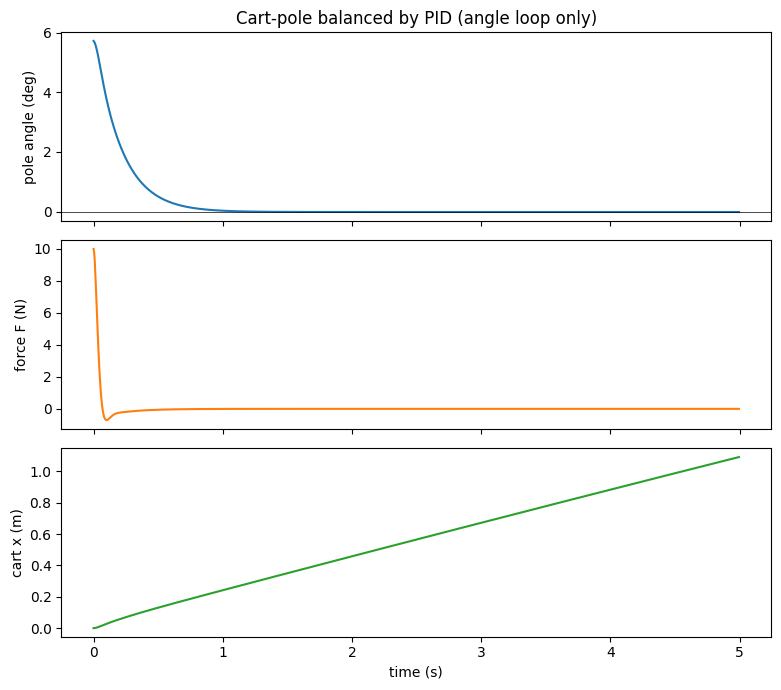

In [35]:
# ---- Cell 6: response plots for the baseline run ----
fig, ax = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
ax[0].plot(log[:, 0], np.degrees(log[:, 2])); ax[0].set_ylabel("pole angle (deg)"); ax[0].axhline(0, c="k", lw=.5)
ax[1].plot(log[:, 0], log[:, 4], c="C1"); ax[1].set_ylabel("force F (N)")
ax[2].plot(log[:, 0], log[:, 1], c="C2"); ax[2].set_ylabel("cart x (m)"); ax[2].set_xlabel("time (s)")
ax[0].set_title("Cart-pole balanced by PID (angle loop only)")
plt.tight_layout(); plt.show()

In [36]:
# ---- Cell 7: live animation (Python simulates, the browser draws it smoothly) ----
import json, uuid
from IPython.display import HTML

_TEMPLATE = """
<div style="font-family:monospace">
<canvas id="c__ID__" width="640" height="260" style="border:1px solid #888;border-radius:6px"></canvas>
<canvas id="p__ID__" width="340" height="260" style="border:1px solid #888;border-radius:6px"></canvas>
</div>
<script>
(function(){
  const D = __DATA__;
  const c = document.getElementById("c__ID__"), p = document.getElementById("p__ID__");
  if (!c || !p) return;
  const g = c.getContext("2d"), q = p.getContext("2d");
  const W = c.width, H = c.height, n = D.t.length, T = D.t[n-1], L = D.L;
  const xmin = Math.min(-1.5, Math.min(...D.x) - 1), xmax = Math.max(1.5, Math.max(...D.x) + 1);
  const sc = Math.min(W / (xmax - xmin), (H - 90) / (L + 0.4)), gy = H - 55;
  const X = v => (v - xmin) * sc;
  const deg = D.th.map(a => a * 180 / Math.PI);
  const maxdeg = Math.max(10, ...deg.map(Math.abs));
  const PW = p.width, PH = p.height, ml = 42;
  const PX = t => ml + (PW - ml - 12) * t / T, PY = d => PH / 2 - (PH / 2 - 28) * d / maxdeg;

  function frame(i, done) {
    // left: cart and pole
    g.clearRect(0, 0, W, H);
    g.strokeStyle = "#888"; g.lineWidth = 2; g.beginPath(); g.moveTo(0, gy); g.lineTo(W, gy); g.stroke();
    g.setLineDash([4, 6]); g.beginPath(); g.moveTo(X(0), gy - 8); g.lineTo(X(0), gy + 8); g.stroke(); g.setLineDash([]);
    const cx = X(D.x[i]), cw = 0.4 * sc, ch = 0.2 * sc;
    g.fillStyle = "#378ADD"; g.fillRect(cx - cw / 2, gy - ch, cw, ch);
    const px = cx + L * sc * Math.sin(D.th[i]), py = gy - ch - L * sc * Math.cos(D.th[i]);
    g.strokeStyle = "#D85A30"; g.lineWidth = 6; g.lineCap = "round";
    g.beginPath(); g.moveTo(cx, gy - ch); g.lineTo(px, py); g.stroke();
    g.fillStyle = "#D85A30"; g.beginPath(); g.arc(px, py, 9, 0, 7); g.fill();
    const fx = D.F[i] * 0.03 * sc;                       // orange bar = how hard the motor pushes
    g.strokeStyle = "#EF9F27"; g.lineWidth = 8; g.lineCap = "butt";
    g.beginPath(); g.moveTo(cx, gy + 22); g.lineTo(cx + fx, gy + 22); g.stroke();
    g.fillStyle = "#888"; g.font = "13px monospace";
    g.fillText("t=" + D.t[i].toFixed(2) + "s  angle=" + deg[i].toFixed(1) + "deg  force=" + D.F[i].toFixed(1) + "N", 10, 20);
    g.fillText("blue dashed tick = start position, orange bar = motor push", 10, H - 8);
    if (D.fell && done) { g.fillStyle = "#E24B4A"; g.font = "bold 28px sans-serif"; g.fillText("FELL OVER", W / 2 - 80, 60); }

    // right: pole angle over time with moving dot
    q.clearRect(0, 0, PW, PH);
    q.strokeStyle = "#888"; q.lineWidth = 1;
    q.beginPath(); q.moveTo(ml, PY(0)); q.lineTo(PW - 12, PY(0)); q.stroke();
    q.beginPath(); q.moveTo(ml, 10); q.lineTo(ml, PH - 20); q.stroke();
    q.fillStyle = "#888"; q.font = "12px monospace";
    q.fillText("+" + maxdeg.toFixed(0), 4, 24); q.fillText("-" + maxdeg.toFixed(0), 4, PH - 24);
    q.fillText("pole angle (deg) vs time", ml + 6, 14); q.fillText("0", 28, PY(0) + 4); q.fillText(T.toFixed(1) + "s", PW - 38, PH - 6);
    q.strokeStyle = "#378ADD"; q.lineWidth = 2; q.beginPath();
    for (let k = 0; k < n; k++) { const x = PX(D.t[k]), y = PY(deg[k]); k ? q.lineTo(x, y) : q.moveTo(x, y); }
    q.stroke();
    q.fillStyle = "#D85A30"; q.beginPath(); q.arc(PX(D.t[i]), PY(deg[i]), 5, 0, 7); q.fill();
  }

  const t0 = performance.now();
  function tick(now) {
    if (!document.body.contains(c)) return;                 // output was replaced: stop
    const tt = ((now - t0) / 1000) % (T + 1.0);             // loop with a 1 s pause at the end
    const done = tt >= T;
    frame(Math.min(n - 1, Math.floor(tt / (T / (n - 1)))), done);
    requestAnimationFrame(tick);
  }
  requestAnimationFrame(tick);
})();
</script>
"""

def animate_run(log, l=0.5, every=2):
    """log from simulate(); every=2 -> one animation frame per 0.01 s of simulated time."""
    idx = np.unique(np.append(np.arange(0, len(log), every), len(log) - 1))
    data = dict(t=log[idx, 0].round(4).tolist(), x=log[idx, 1].round(4).tolist(),
                th=log[idx, 2].round(5).tolist(), F=log[idx, 4].round(3).tolist(),
                L=2 * l, fell=bool(log[-1, 5]))
    return HTML(_TEMPLATE.replace("__ID__", uuid.uuid4().hex[:8]).replace("__DATA__", json.dumps(data)))

In [37]:
# ---- Cell 8: interactive controls: the animation updates while you drag a slider ----
import ipywidgets as w
from IPython.display import display

opts = dict(continuous_update=True, style={"description_width": "150px"}, layout=w.Layout(width="520px"))
kp    = w.FloatSlider(value=100, min=0,    max=200, step=1,     description="Kp  (P: react to lean)", **opts)
ki    = w.FloatSlider(value=1,   min=0,    max=50,  step=0.5,   description="Ki  (I: react to time)", **opts)
kd    = w.FloatSlider(value=20,  min=0,    max=60,  step=0.5,   description="Kd  (D: react to speed)", **opts)
th0   = w.FloatSlider(value=0.1, min=-0.3, max=0.3, step=0.01,  description="start tilt (rad)", **opts)
noise = w.FloatSlider(value=0.0, min=0,    max=0.05, step=0.002, description="sensor noise (rad)", **opts)
umax  = w.FloatSlider(value=30,  min=2,    max=60,  step=1,     description="motor limit (N)", **opts)
shove = w.FloatSlider(value=0,   min=-30,  max=30,  step=1,     description="shove at t=2 s (N)", **opts)
dur   = w.FloatSlider(value=20,  min=5,    max=30,  step=1,     description="run length (s)", **opts)

def show(kp, ki, kd, th0, noise, umax, shove, dur):
    pid = PID(kp, ki, kd, dt=0.005, u_max=umax)
    log = simulate(pid, th0=th0, T=dur, noise_std=noise, push=(2.0, shove, 0.1) if shove else None)
    m = metrics(log)
    print("RESULT:", "FELL OVER" if m["fell"] else f"stayed up, settled in {m['settling_time_s']:.2f} s",
          f"| max tilt {np.degrees(m['max_angle_rad']):.1f} deg | motor effort (rms) {m['effort_rms_N']:.1f} N")
    display(animate_run(log, every=2 if dur <= 10 else 4))

out = w.interactive_output(show, dict(kp=kp, ki=ki, kd=kd, th0=th0, noise=noise, umax=umax, shove=shove, dur=dur))
display(w.VBox([kp, ki, kd, th0, noise, umax, shove, dur]), out)

Output()